# 06. Классификация покрытия

Серое — ядро, белая окантовка — покрытие.
Классы: `coated` и `insufficient_coating` — тонкая, прерывистая или отсутствующая окантовка.
`uncertain` — спорный случай, пустая метка — отсутствие разметки.
Для обучения заполняется таблица меток. Примеры на составных изображениях используются только как ориентир.


In [1]:
from pathlib import Path
import copy
import hashlib
import json
import math
import os
import random
import time

import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

ROOT = Path.cwd().resolve()
if ROOT.name == 'research':
    ROOT = ROOT.parent
DATA = ROOT / 'data_real'
RUN_NAME = 'two_stage_20261024/coating'
OUT = ROOT / 'models' / RUN_NAME
OUT.mkdir(parents=True, exist_ok=True)
CROPS = OUT / 'gt_crops'
CROPS.mkdir(exist_ok=True)
LABELS_CSV = OUT / 'expert_labels.csv'
LOCALIZATION_RUN = ROOT / 'models/two_stage_20261024/localization'
SEED, SIZE, PADDING, BATCH = 42, 320, 0.10, 32
HEAD_EPOCHS, FINETUNE_EPOCHS, PATIENCE = 5, 15, 5
RUN_TRAINING = False  # True только после экспертной разметки.
RUN_CASCADE_EVAL = False
TRAIN_MINUTES, FALLBACK_MINUTES = 54, 3
TRAIN_MINUTES = min(54.0, max(0.01, float(TRAIN_MINUTES)))
FALLBACK_MINUTES = min(3.0, max(0.01, float(FALLBACK_MINUTES)))
IMAGENET_CACHE = Path.home() / '.cache/torch/hub/checkpoints/resnet18-f37072fd.pth'
DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
CLASSES = ('coated', 'insufficient_coating')
REVIEW_LABELS = {'', 'uncertain', *CLASSES}
TARGET_ACCEPTED_ACCURACY, MIN_COVERAGE = 0.90, 0.25
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

## 1. Кропы и метки

Кропы по размеченным bbox с контекстом вокруг окантовки.
ID зависит от изображения и координат. В CSV добавляются только новые ID; прежние метки остаются.


In [2]:
GROUPS = {'train': {'D03', 'D04'}, 'val': {'D01', 'D02'}, 'test': {'D05'}}
EXTENSIONS = {'.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp'}
crop_rows = []
for split, groups in GROUPS.items():
    for path in sorted((DATA / 'images' / split).iterdir()):
        if path.suffix.lower() not in EXTENSIONS:
            continue
        group = path.stem.split('_')[0]
        if group not in groups:
            raise ValueError(f'Нарушено разделение групп: {path}')
        image = Image.open(path).convert('RGB')
        image_hash = hashlib.sha256(path.read_bytes()).hexdigest()
        label = DATA / 'labels' / split / f'{path.stem}.txt'
        for index, row in enumerate(np.loadtxt(label, ndmin=2).reshape(-1, 5)):
            xc, yc, bw, bh = row[1:] * np.array([image.width, image.height, image.width, image.height])
            box = np.array([xc - bw / 2, yc - bh / 2, xc + bw / 2, yc + bh / 2])
            signature = f'{image_hash}:{box.tolist()}:{PADDING}'
            crop_id = f'{path.stem}__' + hashlib.sha256(signature.encode()).hexdigest()[:12]
            bounds = (max(0, math.floor(box[0] - bw * PADDING)), max(0, math.floor(box[1] - bh * PADDING)),
                      min(image.width, math.ceil(box[2] + bw * PADDING)),
                      min(image.height, math.ceil(box[3] + bh * PADDING)))
            crop_path = CROPS / f'{crop_id}.png'
            if not crop_path.exists():
                image.crop(bounds).save(crop_path)
            crop_rows.append(dict(crop_id=crop_id, crop=crop_path.relative_to(ROOT).as_posix(),
                source=path.relative_to(ROOT).as_posix(), source_sha256=image_hash,
                image_id=path.stem, group=group, split=split, bbox_index=index,
                x1=float(box[0]), y1=float(box[1]), x2=float(box[2]), y2=float(box[3]),
                crop_x1=bounds[0], crop_y1=bounds[1], crop_x2=bounds[2], crop_y2=bounds[3]))
manifest = pd.DataFrame(crop_rows)
manifest.to_csv(OUT / 'gt_crops.csv', index=False)
if LABELS_CSV.exists():
    expert = pd.read_csv(LABELS_CSV, dtype=str, keep_default_na=False)
    if set(expert.columns) != {'crop_id', 'label', 'reviewer', 'note'}:
        raise ValueError('Экспертная таблица содержит только crop_id, label, reviewer, note; split/group берутся из исходных кадров.')
    if expert.crop_id.duplicated().any():
        raise ValueError('Повтор crop_id в экспертной таблице.')
else:
    expert = pd.DataFrame(columns=['crop_id', 'label', 'reviewer', 'note'])
new_ids = manifest.loc[~manifest.crop_id.isin(expert.crop_id), ['crop_id']].assign(label='', reviewer='', note='')
if len(new_ids) or not LABELS_CSV.exists():
    expert = pd.concat([expert, new_ids], ignore_index=True)
    expert.to_csv(LABELS_CSV, index=False)
table = manifest.merge(expert, on='crop_id', how='left', validate='one_to_one')
table['label'] = table.label.fillna('').str.strip()
if not set(table.label).issubset(REVIEW_LABELS):
    raise ValueError('Допустимые метки: coated, insufficient_coating, uncertain или пусто.')
table['state'] = table.label.replace('', 'unlabeled')
display(pd.crosstab(table.split, table.state))
print('Редактируемая таблица:', LABELS_CSV.relative_to(ROOT))

state,unlabeled
split,
test,101
train,943
val,223


Редактируемая таблица: models\two_stage_20261024\coating\expert_labels.csv


## 2. Разметка покрытия

В `expert_labels.csv` заполняются `label`, `reviewer`, `note`. `crop_id` остаётся прежним.
После правок повторяется загрузка таблицы. `uncertain` исключается из бинарного обучения.
Достаточность видимой окантовки определяется по согласованным критериям; физическая плотность слоя не измеряется.


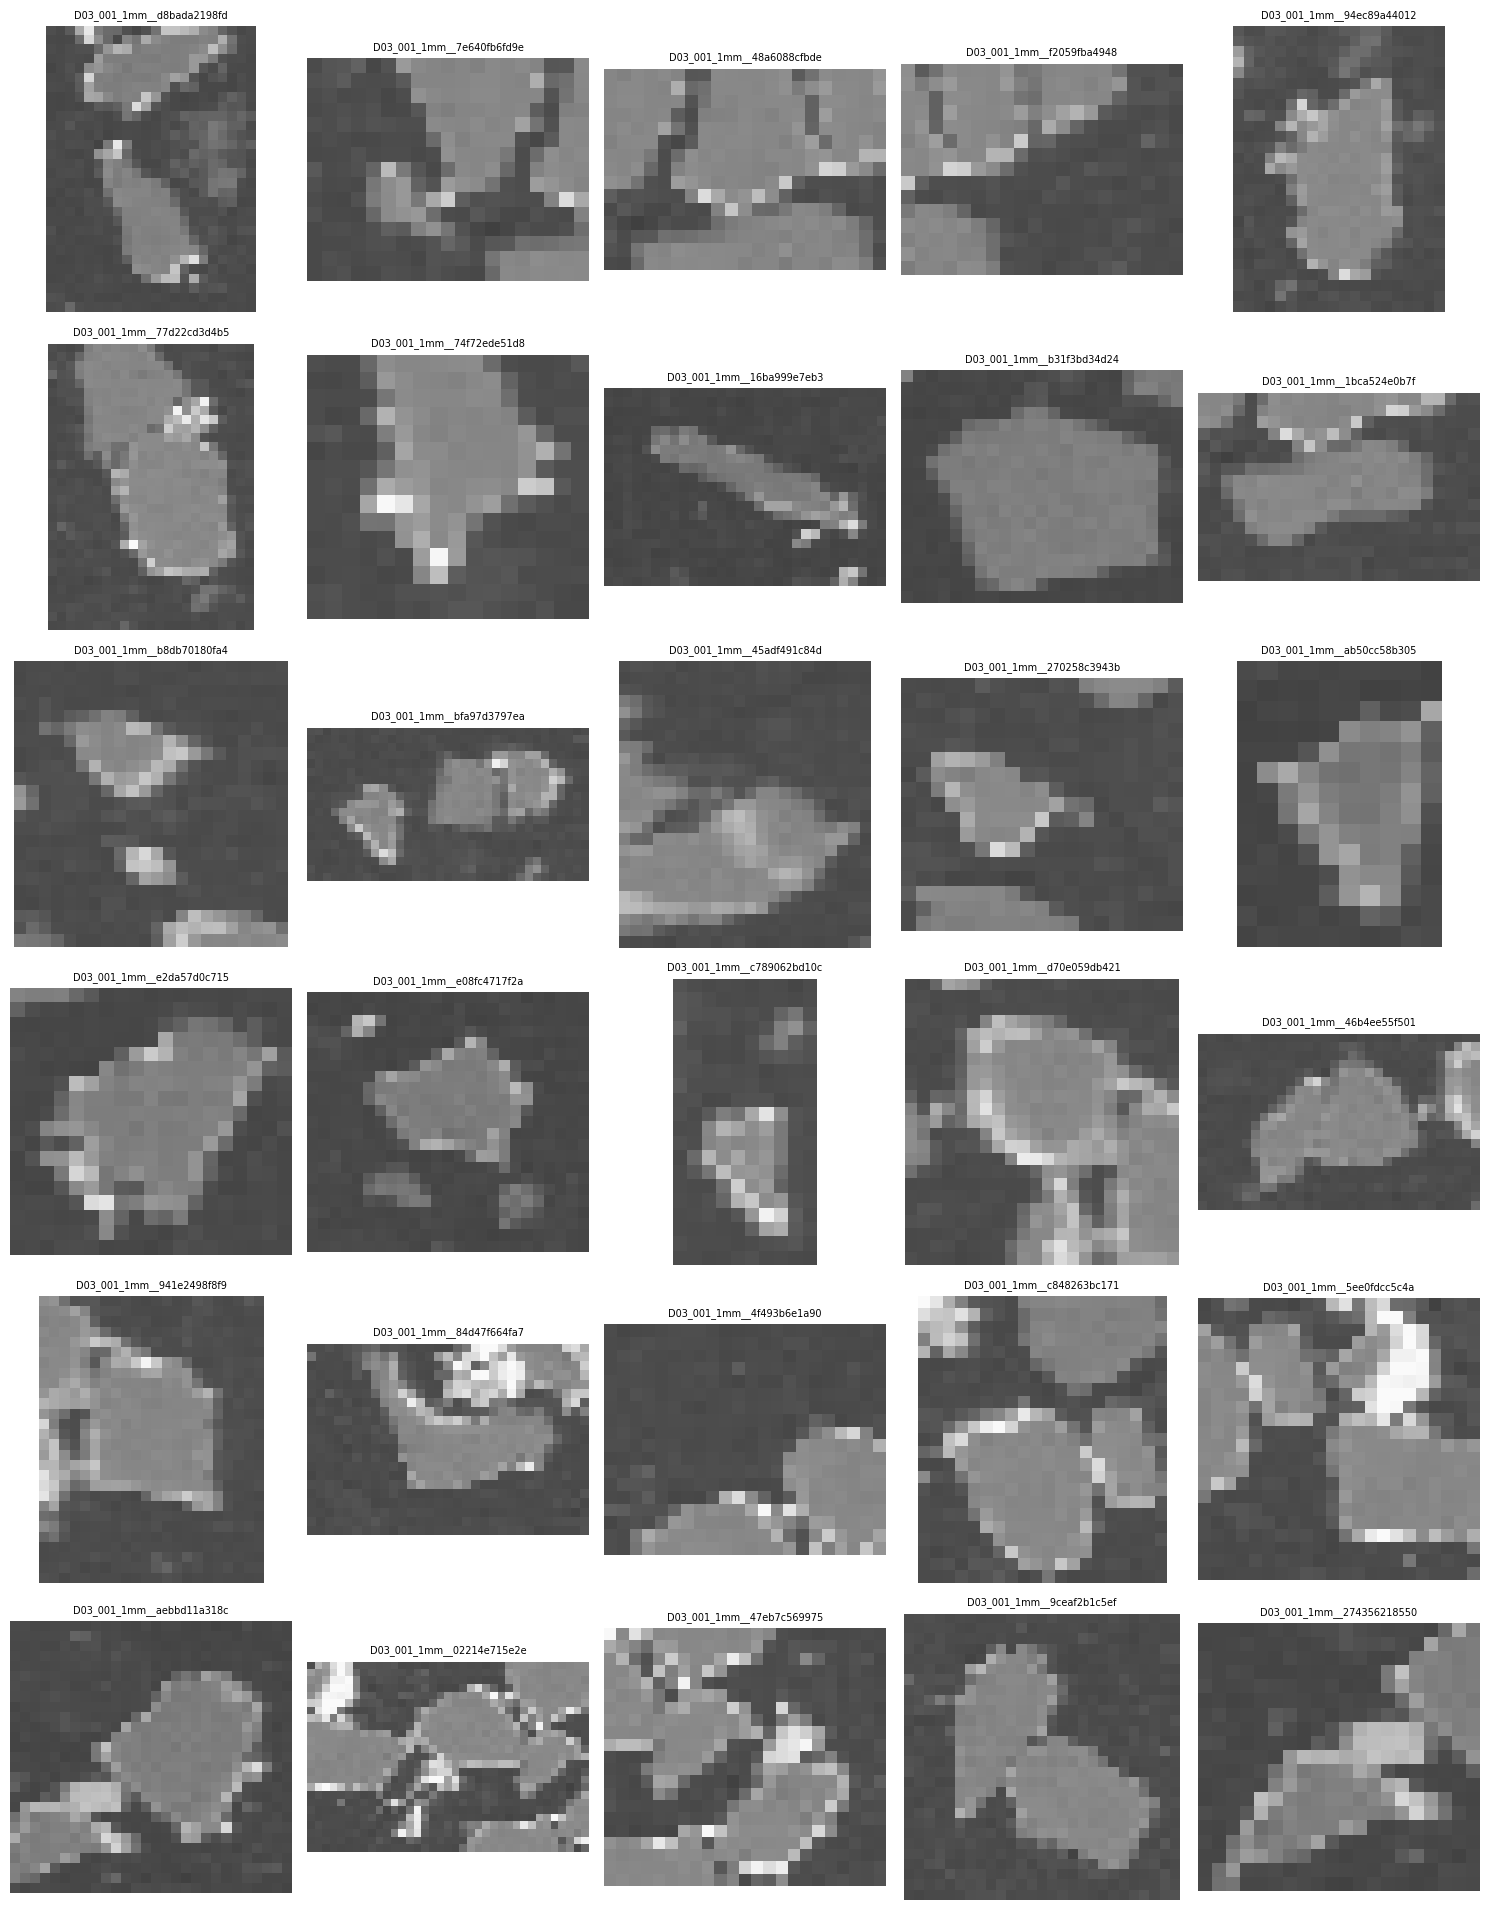

,crop_id,split,group,state,note
0,D03_001_1mm__d8bada2198fd,train,D03,unlabeled,
1,D03_001_1mm__7e640fb6fd9e,train,D03,unlabeled,
2,D03_001_1mm__48a6088cfbde,train,D03,unlabeled,
3,D03_001_1mm__f2059fba4948,train,D03,unlabeled,
4,D03_001_1mm__94ec89a44012,train,D03,unlabeled,
5,D03_001_1mm__77d22cd3d4b5,train,D03,unlabeled,
6,D03_001_1mm__74f72ede51d8,train,D03,unlabeled,
7,D03_001_1mm__16ba999e7eb3,train,D03,unlabeled,
8,D03_001_1mm__b31f3bd34d24,train,D03,unlabeled,
9,D03_001_1mm__1bca524e0b7f,train,D03,unlabeled,


In [3]:
VIEW_SPLIT, VIEW_STATE, PAGE, PAGE_SIZE = 'train', 'unlabeled', 0, 30
view = table.loc[(table.split == VIEW_SPLIT) & (table.state == VIEW_STATE)]
view = view.iloc[PAGE * PAGE_SIZE:(PAGE + 1) * PAGE_SIZE]
if len(view):
    fig, axes = plt.subplots(math.ceil(len(view) / 5), 5, figsize=(15, 3.2 * math.ceil(len(view) / 5)), squeeze=False)
    for ax, (_, row) in zip(axes.flat, view.iterrows()):
        ax.imshow(Image.open(ROOT / row['crop']))
        ax.set_title(row.crop_id, fontsize=7)
        ax.axis('off')
    for ax in list(axes.flat)[len(view):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()
display(view[['crop_id', 'split', 'group', 'state', 'note']])

## 3. Классификатор

ResNet18 с ImageNet-весами. Сначала обучается выходной слой, затем вся сеть.
Размер и пропорции кропа сохраняются через letterbox. Аугментации — отражения и повороты на 90°.
Кропы остаются в выборке исходного кадра.


In [4]:
def letterbox(image, size=SIZE):
    image = image.convert('RGB')
    array = np.asarray(image)
    border = np.concatenate((array[0], array[-1], array[:, 0], array[:, -1]))
    color = tuple(np.median(border, axis=0).astype(int))
    return ImageOps.pad(image, (size, size), method=Image.Resampling.BICUBIC, color=color)


class CropDataset(Dataset):
    def __init__(self, rows, augment=False, size=SIZE):
        self.rows = rows.reset_index(drop=True)
        self.augment = augment
        self.size = size
        self.tensor = transforms.Compose([transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows.iloc[index]
        image = Image.open(ROOT / row['crop']).convert('RGB')
        if self.augment:
            image = image.rotate(random.choice((0, 90, 180, 270)), expand=True)
            if random.random() < 0.5:
                image = ImageOps.mirror(image)
            if random.random() < 0.5:
                image = ImageOps.flip(image)
        tensor = self.tensor(letterbox(image, self.size))
        target = CLASSES.index(row.label) if row.label in CLASSES else -1
        return tensor, target, row.crop_id


confirmed = table.loc[table.label.isin(CLASSES)].copy()
split_groups = {split: set(confirmed.loc[confirmed.split == split, 'group']) for split in GROUPS}
for first, second in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    if split_groups[first] & split_groups[second]:
        raise ValueError('Утечка исходной группы между выборками.')
counts = pd.crosstab(confirmed.split, confirmed.label).reindex(index=GROUPS, columns=CLASSES, fill_value=0)
display(counts)
CAN_TRAIN = bool((counts.loc[['train', 'val']] > 0).all().all())
if not CAN_TRAIN:
    print('Для обучения и выбора параметров нужны оба подтверждённых класса в train и val.')
loaders = {split: DataLoader(CropDataset(confirmed.loc[confirmed.split == split], augment=split == 'train'),
    batch_size=BATCH, shuffle=split == 'train' and bool(len(confirmed.loc[confirmed.split == split])),
    num_workers=0, generator=torch.Generator().manual_seed(SEED)) for split in GROUPS}


def new_classifier(pretrained=False):
    if pretrained and IMAGENET_CACHE.is_file():
        model = models.resnet18(weights=None)
        model.load_state_dict(torch.load(IMAGENET_CACHE, map_location='cpu', weights_only=True))
    else:
        weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        model = models.resnet18(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, len(CLASSES))
    return model.to(DEVICE)


@torch.inference_mode()
def predict_loader(model, loader):
    model.eval()
    rows = []
    for images, targets, ids in loader:
        probabilities = model(images.to(DEVICE)).softmax(1).cpu().numpy()
        for crop_id, target, prob in zip(ids, targets.tolist(), probabilities):
            rows.append(dict(crop_id=crop_id, target=target, predicted=int(prob.argmax()),
                confidence=float(prob.max()), p_coated=float(prob[0]), p_insufficient=float(prob[1])))
    return pd.DataFrame(rows, columns=['crop_id', 'target', 'predicted', 'confidence', 'p_coated', 'p_insufficient'])

label,coated,insufficient_coating
split,,
train,0,0
val,0,0
test,0,0


Для обучения и выбора параметров нужны оба подтверждённых класса в train и val.


## 4. Обучение

До 5 эпох выходного слоя и 15 эпох всей сети; early stopping — 5.
Выбор модели — по val balanced accuracy. Веса классов рассчитываются по train.
Лимит — 54 минуты, затем при необходимости до 3 минут с входом 224 px и обучением выходного слоя.
По умолчанию обучение выключено; веса ImageNet берутся из кэша или загружаются в каталог эксперимента.


In [5]:
def classification_scores(predictions):
    matrix = np.zeros((len(CLASSES), len(CLASSES)), dtype=int)
    for target, predicted in predictions[['target', 'predicted']].itertuples(index=False, name=None):
        if target >= 0:
            matrix[target, predicted] += 1
    tp = np.diag(matrix)
    support = matrix.sum(1)
    precision = np.divide(tp, matrix.sum(0), out=np.zeros(2, dtype=float), where=matrix.sum(0) > 0)
    recall = np.divide(tp, support, out=np.full(2, np.nan), where=support > 0)
    f1 = np.divide(2 * tp, matrix.sum(0) + support, out=np.zeros(2, dtype=float), where=matrix.sum(0) + support > 0)
    return dict(accuracy=float(tp.sum() / max(matrix.sum(), 1)),
        balanced_accuracy=float(np.nanmean(recall)) if support.any() else float('nan'),
        macro_f1=float(np.nanmean(f1)), count=int(matrix.sum())), matrix, precision, recall


MODEL_PATH = OUT / 'best.pt'


def train_classifier(model, name, minutes, size, head_epochs, finetune_epochs):
    directory = OUT / name
    directory.mkdir(exist_ok=False)
    best_path = directory / 'best.pt'
    for loader in loaders.values():
        loader.dataset.size = size
    train_counts = counts.loc['train'].to_numpy(dtype=float)
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(train_counts.sum() / (2 * train_counts),
                                                        dtype=torch.float32, device=DEVICE))
    best_score, history, timed_out = -1.0, [], False
    minutes = min(54.0, max(0.01, float(minutes)))
    begin = time.perf_counter()

    def checkpoint(status, path):
        torch.save(dict(state_dict={k: v.cpu().clone() for k, v in model.state_dict().items()},
            architecture='resnet18', classes=CLASSES, size=size, padding=PADDING,
            seed=SEED, imagenet_weights='IMAGENET1K_V1', status=status,
            labels_sha256=hashlib.sha256(LABELS_CSV.read_bytes()).hexdigest(),
            crops_sha256=hashlib.sha256((OUT / 'gt_crops.csv').read_bytes()).hexdigest(),
            val_balanced_accuracy=best_score), path)

    for stage, epochs, learning_rate in [('head', head_epochs, 1e-3), ('finetune', finetune_epochs, 1e-4)]:
        for parameter in model.parameters():
            parameter.requires_grad = stage == 'finetune'
        for parameter in model.fc.parameters():
            parameter.requires_grad = True
        optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                                      lr=learning_rate, weight_decay=1e-4)
        stale = 0
        for epoch in range(epochs):
            model.train()
            if stage == 'head':
                model.eval()
                model.fc.train()
            running, seen = 0.0, 0
            for images, targets, _ in loaders['train']:
                if time.perf_counter() - begin >= minutes * 60:
                    timed_out = True
                    break
                images, targets = images.to(DEVICE), targets.to(DEVICE)
                optimizer.zero_grad(set_to_none=True)
                loss = criterion(model(images), targets)
                loss.backward()
                optimizer.step()
                running += loss.item() * len(images)
                seen += len(images)
            if timed_out:
                checkpoint('time_limited', directory / 'last.pt')
                break
            val_predictions = predict_loader(model, loaders['val'])
            scores = classification_scores(val_predictions)[0]
            row = dict(stage=stage, epoch=epoch + 1, train_loss=running / max(seen, 1), **scores)
            history.append(row)
            print(row)
            if scores['balanced_accuracy'] > best_score:
                best_score, stale = scores['balanced_accuracy'], 0
                checkpoint('in_progress', best_path)
            else:
                stale += 1
            if stale >= PATIENCE:
                break
        if timed_out:
            break
        if best_path.exists():
            model.load_state_dict(torch.load(best_path, map_location=DEVICE, weights_only=True)['state_dict'])
    status = dict(status='time_limited' if timed_out else 'completed_or_early_stopped',
        elapsed_seconds=time.perf_counter() - begin, size=size, head_epochs=head_epochs,
        finetune_epochs=finetune_epochs, epochs_completed=len(history), minutes=minutes,
        reason='wall_clock_budget' if timed_out else None)
    pd.DataFrame(history).to_csv(directory / 'history.csv', index=False)
    checkpoint(status['status'], directory / 'last.pt')
    if best_path.exists():
        best_checkpoint = torch.load(best_path, map_location='cpu', weights_only=True)
        best_checkpoint['status'] = status['status']
        torch.save(best_checkpoint, best_path)
    (directory / 'status.json').write_text(json.dumps(status, indent=2), encoding='utf-8')
    return best_path if best_path.exists() else directory / 'last.pt', status


if RUN_TRAINING and CAN_TRAIN:
    if MODEL_PATH.exists():
        raise FileExistsError('Checkpoint существует; создайте новый RUN_NAME и сохраните экспертные метки.')
    torch.hub.set_dir(str(OUT / 'pretrained'))
    classifier = new_classifier(pretrained=True)
    best_path, train_status = train_classifier(classifier, 'resnet18_320', TRAIN_MINUTES,
        SIZE, HEAD_EPOCHS, FINETUNE_EPOCHS)
    candidates = [best_path]
    if train_status['status'] == 'time_limited':
        state = torch.load(best_path, map_location=DEVICE, weights_only=True)
        classifier.load_state_dict(state['state_dict'])
        fallback_path, fallback_status = train_classifier(classifier, 'fallback224_head', FALLBACK_MINUTES, 224, 5, 0)
        candidates.append(fallback_path)
        print('Облегчённая попытка:', fallback_status['status'])
    # Checkpoint выбирается по val, test остаётся закрытым.
    best_path = max(candidates, key=lambda path: torch.load(path, map_location='cpu', weights_only=True)['val_balanced_accuracy'])
    MODEL_PATH.write_bytes(best_path.read_bytes())
    print('Выбран checkpoint:', best_path.relative_to(ROOT), '|', train_status['status'])
elif RUN_TRAINING:
    print('Обучение пропущено: нет подтверждённых классов в train/val.')
else:
    print('Обучение выключено; подготовка кропов и экспертной таблицы доступна.')

Обучение выключено; подготовка кропов и экспертной таблицы доступна.


## 5. Порог уверенности

Порог выбирается на val: точность принятых ответов ≥90%, доля принятых ≥25%.
Если условия не выполнены, все ответы направляются на проверку.
Уверенность softmax не гарантирует точность. `uncertain` не является третьим классом сети.


In [6]:
def load_classifier():
    checkpoint = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=True)
    if tuple(checkpoint['classes']) != CLASSES:
        raise ValueError('Несовместимый набор классов checkpoint.')
    model = new_classifier(pretrained=False)
    model.load_state_dict(checkpoint['state_dict'])
    return model.eval(), checkpoint


if MODEL_PATH.exists():
    classifier, checkpoint = load_classifier()
    CLASSIFIER_SIZE = checkpoint['size']
    for loader in loaders.values():
        loader.dataset.size = CLASSIFIER_SIZE
    if checkpoint['labels_sha256'] != hashlib.sha256(LABELS_CSV.read_bytes()).hexdigest():
        print('Экспертные метки изменены после обучения: метрики относятся к сохранённому checkpoint.')
    val_predictions = predict_loader(classifier, loaders['val'])
    val_predictions.to_csv(OUT / 'val_predictions.csv', index=False)
    curve = []
    for threshold in np.linspace(0.5, 0.99, 50):
        accepted = val_predictions.loc[val_predictions.confidence >= threshold]
        curve.append(dict(threshold=float(threshold), accepted=len(accepted),
            coverage=len(accepted) / max(len(val_predictions), 1),
            accuracy=float((accepted.target == accepted.predicted).mean()) if len(accepted) else np.nan))
    curve = pd.DataFrame(curve)
    curve.to_csv(OUT / 'val_risk_coverage.csv', index=False)
    eligible = curve.loc[(curve.accuracy >= TARGET_ACCEPTED_ACCURACY) & (curve.coverage >= MIN_COVERAGE)]
    if set(val_predictions.target) != {0, 1}:
        eligible = eligible.iloc[:0]
        print('В val нет обоих классов; автоматическое решение отключено.')
    THRESHOLD = float(eligible.sort_values(['coverage', 'threshold'], ascending=[False, True]).iloc[0].threshold) if len(eligible) else 1.01
    threshold_config = dict(confidence_threshold=THRESHOLD,
        selected_on='val', target_accuracy=TARGET_ACCEPTED_ACCURACY, min_coverage=MIN_COVERAGE,
        model_sha256=hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest(),
        labels_sha256=hashlib.sha256(LABELS_CSV.read_bytes()).hexdigest())
    (OUT / 'decision.json').write_text(json.dumps(threshold_config, indent=2), encoding='utf-8')
    display(curve.round(3))
    print('Порог:', THRESHOLD, '| 1.01 означает полный отказ.')
else:
    classifier, THRESHOLD, CLASSIFIER_SIZE = None, 1.01, SIZE
    print('Checkpoint отсутствует: классификация остаётся unlabeled.')

Checkpoint отсутствует: классификация остаётся unlabeled.


## 6. Проверка на test

Точность всех размеченных примеров, доля принятых ответов и точность среди них.
Порог фиксируется до оценки. Для спорных примеров считается доля отказов от решения.


In [7]:
if classifier is not None:
    test_predictions = predict_loader(classifier, loaders['test'])
    if set(test_predictions.target) != {0, 1}:
        print('В test нет обоих классов; оценка неполная, общей точностью её считать нельзя.')
    test_predictions['accepted'] = test_predictions.confidence >= THRESHOLD
    test_predictions = test_predictions.merge(table[['crop_id', 'image_id', 'group']], on='crop_id')
    test_predictions.to_csv(OUT / 'test_predictions.csv', index=False)
    metrics, matrix, precision, recall = classification_scores(test_predictions)
    accepted = test_predictions.loc[test_predictions.accepted]
    metrics.update(coverage=len(accepted) / max(len(test_predictions), 1),
        accepted_accuracy=float((accepted.target == accepted.predicted).mean()) if len(accepted) else None)
    display(pd.DataFrame([metrics]).round(4))
    display(pd.DataFrame(matrix, index=CLASSES, columns=CLASSES))
    display(pd.DataFrame(dict(class_name=CLASSES, precision=precision, recall=recall)).round(4))
    by_frame = test_predictions.assign(correct=test_predictions.target == test_predictions.predicted).groupby('image_id').agg(
        count=('crop_id', 'count'), accuracy=('correct', 'mean'), coverage=('accepted', 'mean'))
    by_frame.to_csv(OUT / 'test_by_frame.csv')
    display(by_frame.round(3))
    uncertain = table.loc[(table.label == 'uncertain') & (table.split.isin(['val', 'test']))]
    if len(uncertain):
        uncertain_predictions = predict_loader(classifier, DataLoader(CropDataset(uncertain, size=CLASSIFIER_SIZE), batch_size=BATCH))
        uncertain_predictions['rejected'] = uncertain_predictions.confidence < THRESHOLD
        uncertain_predictions.to_csv(OUT / 'expert_uncertain_predictions.csv', index=False)
        print('Отказ на экспертном uncertain:', uncertain_predictions.rejected.mean())

## 7. Детекция и классификация

Детектор из 05 вырезает кропы для классификатора.
`uncertain` в ответе означает низкую уверенность, `unlabeled` — отсутствие обученного классификатора.


In [8]:
os.environ['YOLO_CONFIG_DIR'] = str(OUT / 'ultralytics')
Path(os.environ['YOLO_CONFIG_DIR']).mkdir(parents=True, exist_ok=True)
from ultralytics import YOLO
from torchvision.ops import box_iou, nms


def detect_and_classify(image_path, save_to=None):
    config_path = LOCALIZATION_RUN / 'selected_pipeline.json'
    config = json.loads(config_path.read_text(encoding='utf-8'))
    detector = YOLO(str(ROOT / config['weights']), task='detect')
    source = Image.open(image_path).convert('RGB')
    width, height = source.size

    def raw(image):
        result = detector.predict(image, imgsz=config['imgsz'], conf=config['ap_conf'], iou=0.7,
            max_det=config['max_det'], device=0 if DEVICE.type == 'cuda' else 'cpu',
            verbose=False, rect=True, half=False, save=False)[0]
        return torch.cat((result.boxes.xyxy.cpu(), result.boxes.conf.cpu()[:, None]), 1)

    def tile_starts(length, size):
        if length <= size:
            return [0]
        step = max(1, round(size * (1 - config['overlap'])))
        return sorted(set([*range(0, length - size + 1, step), length - size]))

    all_boxes = [raw(source)]
    tile_size = config['tile_size']
    if tile_size:
        for y in tile_starts(height, tile_size):
            for x in tile_starts(width, tile_size):
                x2, y2 = min(x + tile_size, width), min(y + tile_size, height)
                boxes = raw(source.crop((x, y, x2, y2)))
                complete = torch.ones(len(boxes), dtype=torch.bool)
                if x > 0:
                    complete &= boxes[:, 0] > 3
                if y > 0:
                    complete &= boxes[:, 1] > 3
                if x2 < width:
                    complete &= boxes[:, 2] < x2 - x - 3
                if y2 < height:
                    complete &= boxes[:, 3] < y2 - y - 3
                boxes = boxes[complete]
                boxes[:, :4] += torch.tensor([x, y, x, y])
                all_boxes.append(boxes)
    boxes = torch.cat(all_boxes)
    if len(boxes):
        boxes = boxes[nms(boxes[:, :4], boxes[:, 4], config['merge_iou'])[:config['max_det']]]
        boxes = boxes[boxes[:, 4] >= config['confidence']]
    rows = []
    tensor_transform = CropDataset(pd.DataFrame()).tensor
    for index, box in enumerate(boxes.numpy()):
        x1, y1, x2, y2 = map(float, box[:4])
        dx, dy = (x2 - x1) * PADDING, (y2 - y1) * PADDING
        bounds = (max(0, math.floor(x1 - dx)), max(0, math.floor(y1 - dy)),
                  min(width, math.ceil(x2 + dx)), min(height, math.ceil(y2 + dy)))
        crop = source.crop(bounds)
        row = dict(source=str(Path(image_path).resolve()), detection_index=index,
            x1=x1, y1=y1, x2=x2, y2=y2, detector_confidence=float(box[4]),
            model_label='unlabeled', class_confidence=None, p_coated=None, p_insufficient=None)
        if classifier is not None:
            with torch.inference_mode():
                probability = classifier(tensor_transform(letterbox(crop, CLASSIFIER_SIZE)).unsqueeze(0).to(DEVICE)).softmax(1)[0].cpu().numpy()
            confidence = float(probability.max())
            row.update(model_label=CLASSES[int(probability.argmax())] if confidence >= THRESHOLD else 'uncertain',
                class_confidence=confidence, p_coated=float(probability[0]), p_insufficient=float(probability[1]))
        rows.append(row)
    result = pd.DataFrame(rows)
    if save_to is not None:
        target = Path(save_to).resolve()
        if OUT.resolve() not in target.parents:
            raise ValueError('Результат сохраняется внутри каталога этого эксперимента.')
        result.to_csv(target, index=False)
    return result


# Пример после выполнения 05:
# result = detect_and_classify(DATA / 'images/test/D05_001_400um.png', OUT / 'pipeline_preview.csv')
# display(result)

## 8. Оценка пайплайна

`RUN_CASCADE_EVAL=True` включает оценку на test. Рамки сопоставляются при IoU ≥0.50.
Считаются пропуски, точность классов, доля отказов и доля одновременно найденных и верно классифицированных частиц.
Неполная разметка может увеличивать число ложных срабатываний.


In [9]:
def evaluate_cascade(split='test'):
    frame_rows, match_rows = [], []
    for image_id, gt in table.loc[table.split == split].groupby('image_id'):
        gt = gt.reset_index(drop=True)
        result = detect_and_classify(ROOT / gt.iloc[0].source)
        if len(result):
            result = result.sort_values('detector_confidence', ascending=False).reset_index(drop=True)
            ious = box_iou(torch.tensor(result[['x1', 'y1', 'x2', 'y2']].to_numpy(dtype=np.float32)),
                           torch.tensor(gt[['x1', 'y1', 'x2', 'y2']].to_numpy(dtype=np.float32))).numpy()
        else:
            ious = np.empty((0, len(gt)))
        used, assigned = set(), {}
        for pred_index, overlaps in enumerate(ious):
            for gt_index in np.argsort(-overlaps):
                if overlaps[gt_index] < 0.5:
                    break
                if int(gt_index) not in used:
                    used.add(int(gt_index))
                    assigned[int(gt_index)] = pred_index
                    break
        for gt_index, row in gt.iterrows():
            pred_index = assigned.get(gt_index)
            model_label = result.iloc[pred_index].model_label if pred_index is not None else 'missed'
            match_rows.append(dict(image_id=image_id, crop_id=row.crop_id,
                expert_label=row.label or 'unlabeled', detected=pred_index is not None,
                model_label=model_label, accepted=model_label in CLASSES,
                correct=model_label == row.label if row.label in CLASSES else None))
        frame_rows.append(dict(image_id=image_id, gt=len(gt), predicted=len(result),
                               tp=len(used), fn=len(gt) - len(used), fp=len(result) - len(used)))
    matches, frames = pd.DataFrame(match_rows), pd.DataFrame(frame_rows)
    confirmed = matches.loc[matches.expert_label.isin(CLASSES)]
    matched = confirmed.loc[confirmed.detected]
    accepted = matched.loc[matched.accepted]
    summary = dict(gt=int(frames.gt.sum()), detector_tp=int(frames.tp.sum()),
        detector_fn=int(frames.fn.sum()), detector_fp=int(frames.fp.sum()),
        confirmed_gt=len(confirmed), confirmed_detected=len(matched),
        accepted=len(accepted),
        matched_coverage=len(accepted) / max(len(matched), 1),
        accepted_accuracy=float(accepted.correct.astype(bool).mean()) if len(accepted) else None,
        correct_accepted_over_all_confirmed=float(accepted.correct.astype(bool).sum() / max(len(confirmed), 1)))
    matches.to_csv(OUT / f'{split}_cascade_matches.csv', index=False)
    frames.to_csv(OUT / f'{split}_cascade_frames.csv', index=False)
    (OUT / f'{split}_cascade_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
    return summary, frames, matches


if RUN_CASCADE_EVAL and classifier is not None:
    cascade_summary, cascade_frames, cascade_matches = evaluate_cascade('test')
    display(pd.DataFrame([cascade_summary]).round(4))
    display(cascade_frames)
elif RUN_CASCADE_EVAL:
    print('Цепочка не оценивается: сначала требуется обученный классификатор.')

## Источники

[PyTorch](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html) — перенос обучения.
[Selective classification](https://arxiv.org/abs/1705.08500) — отказ от ответа при низкой уверенности.
[Uncertainty-aware SEM segmentation](https://www.nature.com/articles/s41524-024-01302-w) — неоднозначность частиц на SEM-снимках.
Для итоговой проверки нужны подтверждённые метки и новые образцы.
